### Start with a label and all 8 features. Iterate through 7/8 feature combinations to find the feature with least impact. Drop the feature and iterate to the next 6/7 features... continue until F1 score is not improving anymore

In [9]:
from import_vossi import data_import, find_best_feature_to_drop, Classifier

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import svm

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 8,           # Matches ootnotesize
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "figure.titlesize": 9
})
import pandas as pd

In [10]:
clf_log_reg = LogisticRegression(class_weight="balanced")
clf_svmlin = svm.SVC(kernel='linear', C=1, coef0=0.0, tol=1e-3) 
clf_svmrbf = svm.SVC(kernel='rbf', C=10, gamma='scale', tol=1e-3)
clf_svmpoly = svm.SVC(kernel='poly', degree=3, C=1, coef0=0.0, tol=1e-3)

active_model = clf_log_reg  # Set the active model to the linear SVM


### Implementing a Loop that cycles through all labels to determine the ideal features.

In [11]:
files = ["SNR_20db", "SNR_30db", "SNR_40db", "SNR_50db", "SNR_noiseless"]
target_labels = ["Sag", "Sag_harmonics", "Transient", "Swell_harmonics", "Normal", "Flicker", "Harmonics", "Swell", "Interruption"]
features = ["F1", "F2", "F3", "F4", "F5", "F6", "F7", "F8"]


# Create a DataFrame to store the ideal features for each target label
ideal_features = pd.DataFrame(columns=["Target Label", "Best Feature to Drop", "F1 Score", "Features to Use"])

# Create a list to store the results for each target label (Append to this list and then convert to DataFrame at the end)
rows = []


# Iterate through each target label and find the best features to drop
for target_label in target_labels:
    feature_dropped = [] # Initialize an empty list to keep track of dropped features for the current target label
    best_f1_n0 = 0 # Initial value for the global best F1 score with all features

    while best_f1_n0 is not None and len(feature_dropped) < 7:  # Ensure we don't drop all features
        best_feature_to_drop, best_f1 = find_best_feature_to_drop(files, features, target_label, feature_dropped, best_f1_n0, active_model)  # Pass the SVM model to the function

        if best_f1 is not None: # Check if a valid best F1 score was returned
            feature_dropped.append(best_feature_to_drop)
            best_f1_n0 = best_f1
        else:                   # If no valid best F1 score was returned, break the loop
            print(f"\nNo further improvement in F1 score of {target_label}. Stopping the feature dropping process.")
            print(f"Final features dropped: {feature_dropped}, Final best F1 score: {best_f1_n0}")
            break
    rows.append({"Target Label": target_label, "Best Feature to Drop": feature_dropped, "F1 Score": best_f1_n0, "Features to Use": [f for f in features if f not in feature_dropped]})
ideal_features = pd.DataFrame(rows)
print(ideal_features.drop(columns=["Best Feature to Drop"]))


No further improvement in F1 score of Sag. Stopping the feature dropping process.
Final features dropped: ['F5', 'F3', 'F7', 'F2'], Final best F1 score: 0.9001838371547194

No further improvement in F1 score of Sag_harmonics. Stopping the feature dropping process.
Final features dropped: ['F2'], Final best F1 score: 0.7188979445760776

No further improvement in F1 score of Transient. Stopping the feature dropping process.
Final features dropped: ['F4', 'F8', 'F3', 'F6'], Final best F1 score: 0.8929799634300614

No further improvement in F1 score of Swell_harmonics. Stopping the feature dropping process.
Final features dropped: ['F4', 'F8'], Final best F1 score: 0.7574501806749954

No further improvement in F1 score of Normal. Stopping the feature dropping process.
Final features dropped: ['F8', 'F5', 'F4', 'F6', 'F3'], Final best F1 score: 0.6572356373806101

No further improvement in F1 score of Flicker. Stopping the feature dropping process.
Final features dropped: ['F8', 'F4', 'F5'

# Print Conf. Matrix, Metrics and the Probabilities per Sample

SVM - Sag - Iterations: [20]


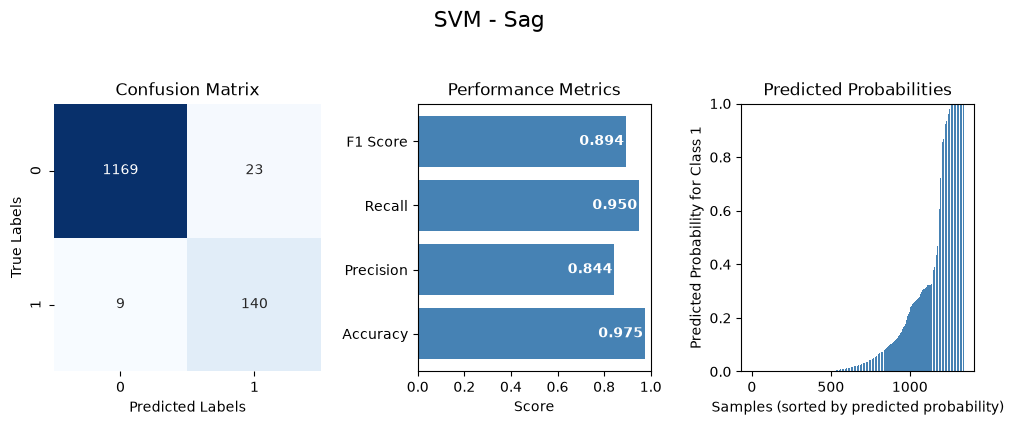

SVM - Sag_harmonics - Iterations: [20]


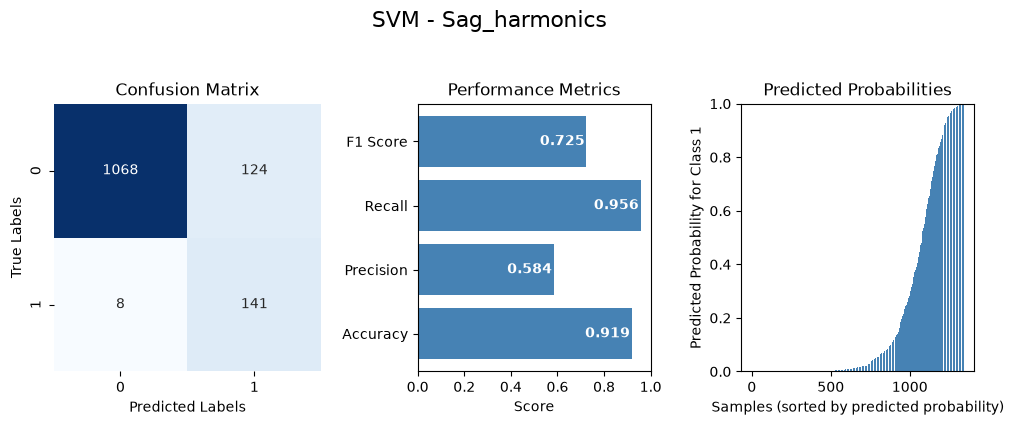

SVM - Transient - Iterations: [17]


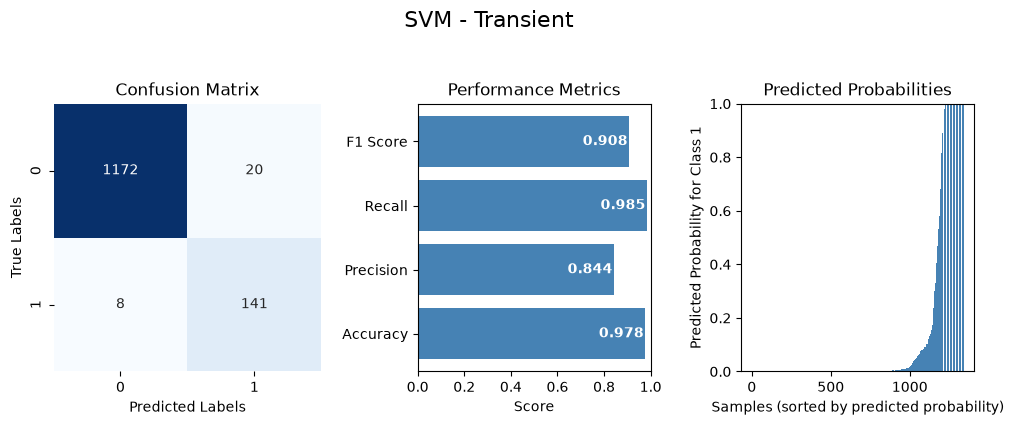

SVM - Swell_harmonics - Iterations: [19]


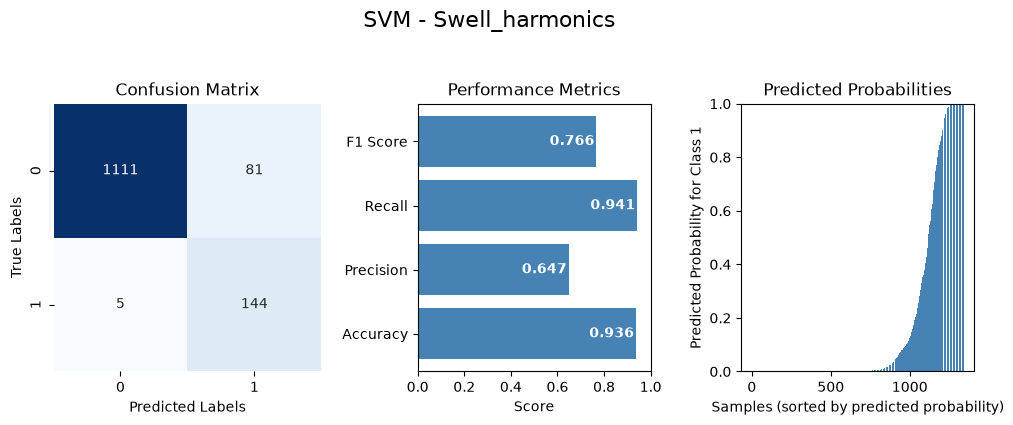

SVM - Normal - Iterations: [13]


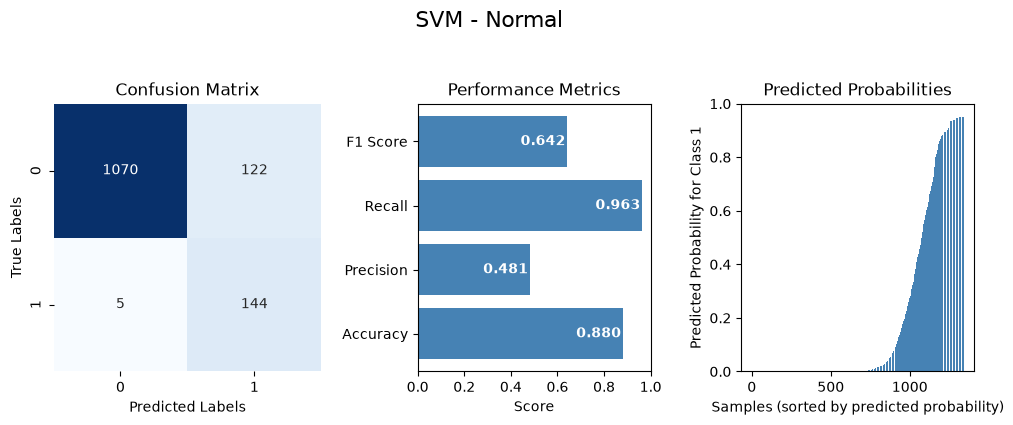

SVM - Flicker - Iterations: [11]


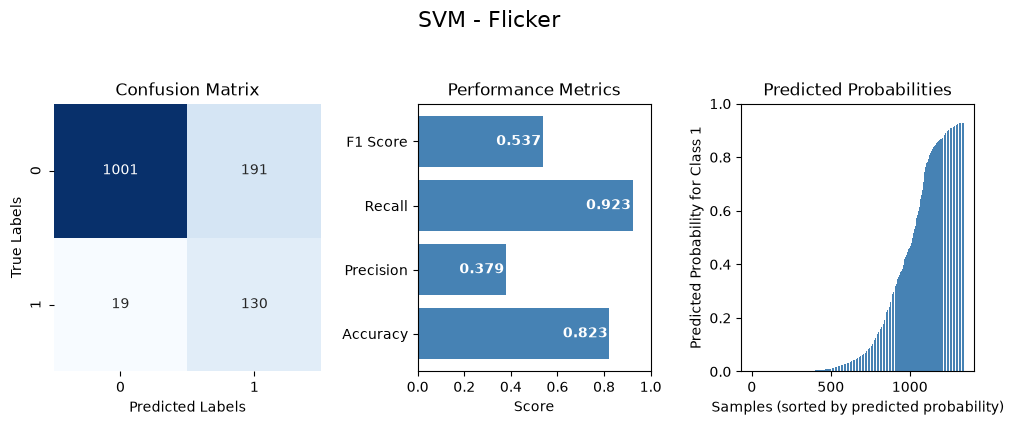

SVM - Harmonics - Iterations: [14]


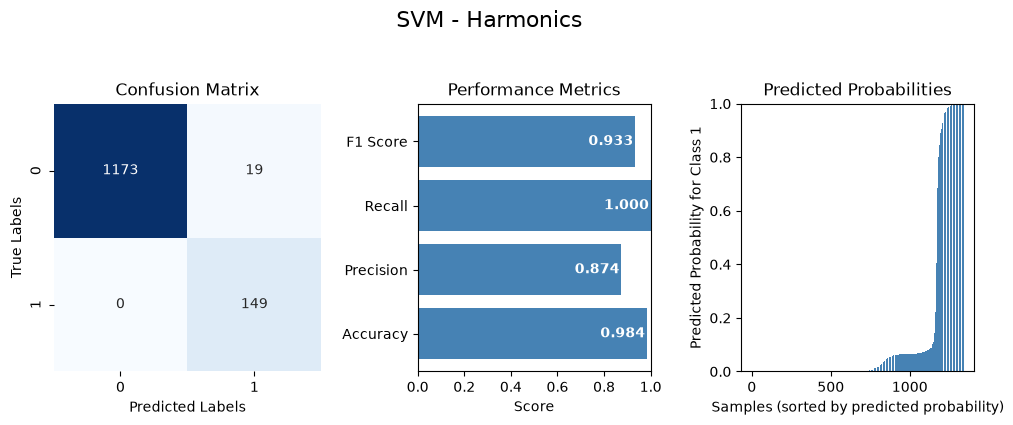

SVM - Swell - Iterations: [11]


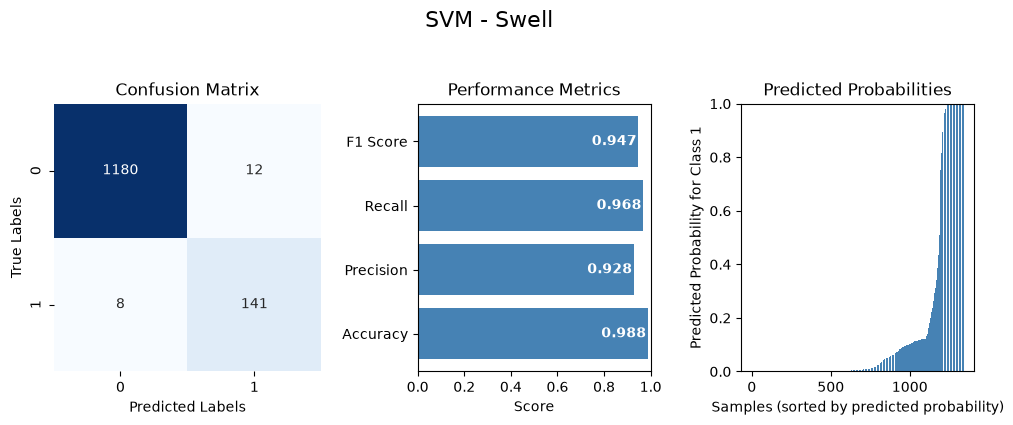

SVM - Interruption - Iterations: [13]


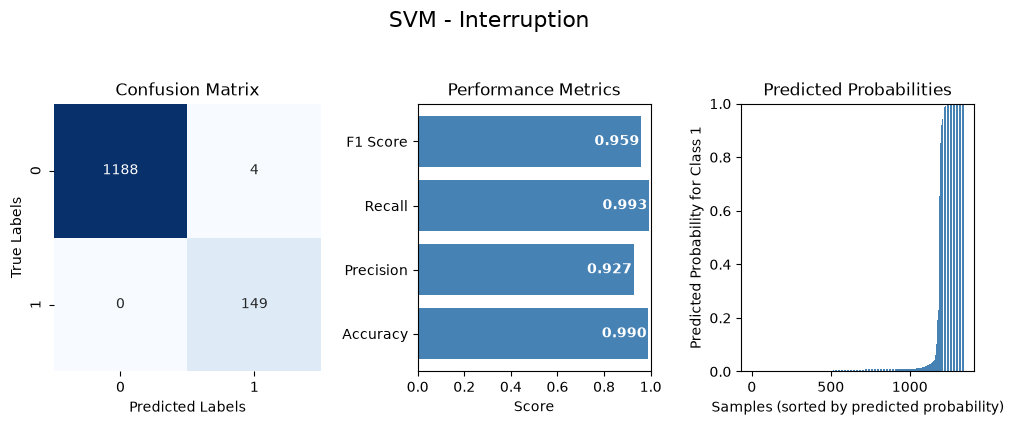

      Target Label  Accuracy  Precision    Recall  F1 Score
8     Interruption  0.990492   0.926963  0.993291  0.958820
7            Swell  0.988069   0.927864  0.968132  0.947488
6        Harmonics  0.983967   0.874255  1.000000  0.932822
2        Transient  0.977815   0.843513  0.984925  0.908483
0              Sag  0.974832   0.843707  0.949656  0.893506
3  Swell_harmonics  0.936242   0.647371  0.941357  0.766379
1    Sag_harmonics  0.918717   0.584228  0.956390  0.724526
4           Normal  0.880500   0.481263  0.963090  0.641738
5          Flicker  0.823266   0.378927  0.922830  0.537205
      Target Label  Accuracy  Precision    Recall  F1 Score
8     Interruption  0.997017   0.986928  0.998322  0.992537
6        Harmonics  0.985831   0.943452  0.992030  0.966015
7            Swell  0.985086   0.957417  0.968121  0.962686
2        Transient  0.979120   0.934498  0.964765  0.948937
0              Sag  0.976137   0.925628  0.960151  0.941967
3  Swell_harmonics  0.935869   0.817760 

In [12]:
feature_sets = [ideal_features["Features to Use"].iloc[0], ideal_features["Features to Use"].iloc[1], ideal_features["Features to Use"].iloc[2], ideal_features["Features to Use"].iloc[3], ideal_features["Features to Use"].iloc[4], ideal_features["Features to Use"].iloc[5], ideal_features["Features to Use"].iloc[6], ideal_features["Features to Use"].iloc[7], ideal_features["Features to Use"].iloc[8]]

score_rows = []
score_rows_test = []

for target_label, features in zip(target_labels, feature_sets):
    data, sample_labels = data_import(files, features)
    full_data = pd.DataFrame(data, columns=features)

    # Change labels to binary classification: 1 for the target class, 0 for all other events
    binary_labels = [int(sample_label == target_label) for sample_label in sample_labels]

    # add labels to the dataframe
    full_data['Label'] = binary_labels

    X_train, X_test, y_train, y_test = train_test_split(data, binary_labels, test_size=0.2, random_state=12, stratify=binary_labels)
    

    metrics, metrics_test = Classifier(active_model, X_train, y_train, X_test, y_test, title="SVM - " + target_label)

    # Add the results to the score list
    score_rows.append({"Target Label": target_label, **metrics})
    score_rows_test.append({"Target Label": target_label, **metrics_test})

score_list = pd.DataFrame(score_rows)
# sort by F1 Score in descending order
score_list = score_list.sort_values(by='F1 Score', ascending=False)
print(score_list)

score_list_test = pd.DataFrame(score_rows_test)
# sort by F1 Score in descending order
score_list_test = score_list_test.sort_values(by='F1 Score', ascending=False)
print(score_list_test)